# Detection of Clinical Mastitis in Dairy Cows


 The target column is`class1`.

 `class1 = 1` means mastitis is present and `class1 = 0` means absent.

## 1. Install PySpark and upload the dataset



In [29]:
!pip install pyspark -q
from google.colab import files

uploaded = files.upload()

Saving clinical_mastitis_cows_version1.csv to clinical_mastitis_cows_version1.csv


## 2. Spark Session

In [30]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.appName("MastitisDetection").getOrCreate()


## 3. Load and inspect the data

In [31]:
df = spark.read.csv("clinical_mastitis_cows_version1.csv", header=True, inferSchema=True)

# rename cols
df = df.withColumnRenamed("Months after giving birth", "Months_after_birth")
df = df.withColumnRenamed("Previous_Mastits_status", "Previous_Mastitis")

df.printSchema()
print("Rows:", df.count())
print("Columns:", len(df.columns))
df.show(5)

root
 |-- Cow_ID: string (nullable = true)
 |-- Day: integer (nullable = true)
 |-- Breed: string (nullable = true)
 |-- Months_after_birth: integer (nullable = true)
 |-- Previous_Mastitis: integer (nullable = true)
 |-- IUFL: integer (nullable = true)
 |-- EUFL: integer (nullable = true)
 |-- IUFR: integer (nullable = true)
 |-- EUFR: integer (nullable = true)
 |-- IURL: integer (nullable = true)
 |-- EURL: integer (nullable = true)
 |-- IURR: integer (nullable = true)
 |-- EURR: integer (nullable = true)
 |-- Temperature: integer (nullable = true)
 |-- Hardness: integer (nullable = true)
 |-- Pain: integer (nullable = true)
 |-- Milk_visibility: integer (nullable = true)
 |-- class1: integer (nullable = true)

Rows: 6600
Columns: 18
+------+---+------+------------------+-----------------+----+----+----+----+----+----+----+----+-----------+--------+----+---------------+------+
|Cow_ID|Day| Breed|Months_after_birth|Previous_Mastitis|IUFL|EUFL|IUFR|EUFR|IURL|EURL|IURR|EURR|Temperature|

## 4. Exploring dataset


In [32]:
df.createOrReplaceTempView("mastitis")

print("Class distribution:")
spark.sql("""
SELECT class1, COUNT(*) AS records,
       ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM mastitis), 2) AS percentage
FROM mastitis
GROUP BY class1
ORDER BY class1
""").show()

print("Average measurements by class:")
spark.sql("""
SELECT class1, ROUND(AVG(IUFL), 2) AS avg_IUFL,
       ROUND(AVG(EUFL), 2) AS avg_EUFL,
       ROUND(AVG(Temperature), 2) AS avg_temperature
FROM mastitis
GROUP BY class1
ORDER BY class1
""").show()

print("Records by breed:")
spark.sql("""
SELECT Breed, COUNT(*) AS records, SUM(class1) AS class1_positive_records
FROM mastitis
GROUP BY Breed
ORDER BY records DESC
""").show()

Class distribution:
+------+-------+----------+
|class1|records|percentage|
+------+-------+----------+
|     0|   5490|     83.18|
|     1|   1110|     16.82|
+------+-------+----------+

Average measurements by class:
+------+--------+--------+---------------+
|class1|avg_IUFL|avg_EUFL|avg_temperature|
+------+--------+--------+---------------+
|     0|  197.67|  229.19|           42.9|
|     1|  249.75|  290.45|          48.57|
+------+--------+--------+---------------+

Records by breed:
+--------+-------+-----------------------+
|   Breed|records|class1_positive_records|
+--------+-------+-----------------------+
|  Jersey|   6498|                   1092|
|hostlene|    102|                     18|
+--------+-------+-----------------------+



## 5. Excluding some input features

`class1` is the target value.

My initial observation of the dataset showed that `Milk_visibility` , `Hardness` and `Pain` had more or less same values as target column. Hence we confirm that hypothesis using a function

We will use the udder measurements, temperature, breed, months after birth, and previous mastitis status.

In [33]:
total = df.count()
for c in ["Hardness", "Pain", "Milk_visibility"]:
    same = df.filter(df[c] == df["class1"]).count()
    print(c, "matches class1 in", same, "of", total, "rows")

Hardness matches class1 in 6558 of 6600 rows
Pain matches class1 in 6576 of 6600 rows
Milk_visibility matches class1 in 6600 of 6600 rows


## 6. Split training and testing data by cow

We have 6 records per cow indicating values were taken over 6 days. To ensure same cow doesn't appear in both train and test we split by cow(Cow_ID)

In [34]:
cows = df.select("Cow_ID").distinct()
train_cows, test_cows = cows.randomSplit([0.8, 0.2], seed=42)

train_raw = df.join(train_cows, "Cow_ID")
test_raw = df.join(test_cows, "Cow_ID")

print("Training cows:", train_cows.count())
print("Testing cows:", test_cows.count())
print("Training rows:", train_raw.count())
print("Testing rows:", test_raw.count())

Training cows: 915
Testing cows: 185
Training rows: 5490
Testing rows: 1110


## 7. Converting the data into ML features


In [35]:
from pyspark.ml.feature import StringIndexer, VectorAssembler, MinMaxScaler

train_raw = train_raw.withColumn("label", F.col("class1").cast("double"))
test_raw = test_raw.withColumn("label", F.col("class1").cast("double"))

# Convert breed names to numeric values
indexer = StringIndexer(inputCol="Breed", outputCol="Breed_idx", handleInvalid="keep")
indexer_model = indexer.fit(train_raw)
train_indexed = indexer_model.transform(train_raw)
test_indexed = indexer_model.transform(test_raw)

# Features used for prediction
feature_cols = [
    "IUFL", "EUFL", "IUFR", "EUFR", "IURL", "EURL", "IURR", "EURR",
    "Temperature", "Months_after_birth", "Previous_Mastitis", "Breed_idx"
]
print("Features used:", feature_cols)

assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features")
train_assembled = assembler.transform(train_indexed)
test_assembled = assembler.transform(test_indexed)

# Scale the features using the training data
scaler = MinMaxScaler(inputCol="raw_features", outputCol="features")
scaler_model = scaler.fit(train_assembled)
train = scaler_model.transform(train_assembled)
test = scaler_model.transform(test_assembled)

train.select("Cow_ID", "features", "label").show(3, truncate=60)

Features used: ['IUFL', 'EUFL', 'IUFR', 'EUFR', 'IURL', 'EURL', 'IURR', 'EURR', 'Temperature', 'Months_after_birth', 'Previous_Mastitis', 'Breed_idx']
+------+------------------------------------------------------------+-----+
|Cow_ID|                                                    features|label|
+------+------------------------------------------------------------+-----+
|  cow1|[0.10416666666666666,0.12727272727272726,0.09389671361502...|  0.0|
|  cow1|[0.11458333333333333,0.12727272727272726,0.10328638497652...|  0.0|
|  cow1|[0.11458333333333333,0.13636363636363635,0.10798122065727...|  0.0|
+------+------------------------------------------------------------+-----+
only showing top 3 rows


## 8. Correlation heatmap

The heatmap shows the correlations between the feautres we have selected.

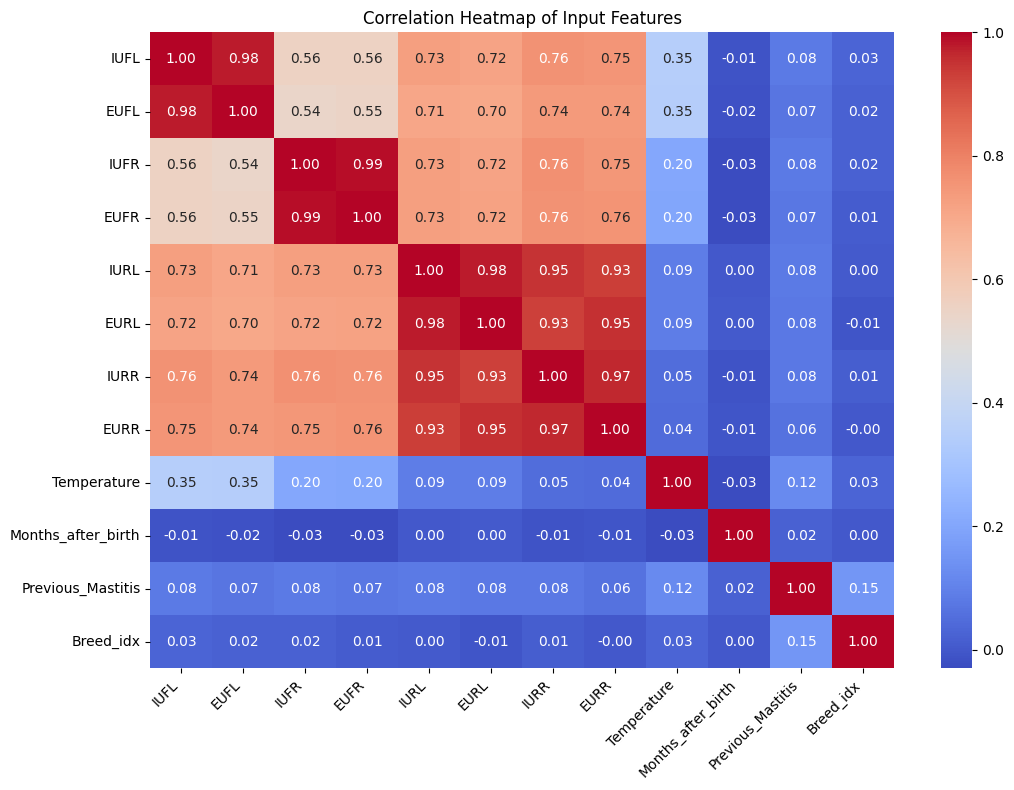

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.stat import Correlation

correlation = Correlation.corr(train, "raw_features", "pearson")
corr = correlation.head()[0].toArray()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            xticklabels=feature_cols, yticklabels=feature_cols)
plt.title("Correlation Heatmap of Input Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Train the models

I have trained 4 models. Linear Regression, Decision Tree, Naive Bayes, SVM.

In [37]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, NaiveBayes, LinearSVC

# Logistic Regression
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100)
lr_model = lr.fit(train)

# Decision Tree
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", maxDepth=5, seed=42)
dt_model = dt.fit(train)

# Naive Bayes
nb = NaiveBayes(featuresCol="features", labelCol="label", modelType="gaussian")
nb_model = nb.fit(train)

# Support Vector Machine (binary classification)
svm = LinearSVC(featuresCol="features", labelCol="label", maxIter=100)
svm_model = svm.fit(train)

print("training completed")

training completed


## 10. Prediction and Evaluation

In [43]:
lr_predictions = lr_model.transform(test)
dt_predictions = dt_model.transform(test)
nb_predictions = nb_model.transform(test)
svm_predictions = svm_model.transform(test)

from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
import pandas as pd

accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="accuracy")
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="precisionByLabel")
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="recallByLabel")
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="fMeasureByLabel")

precision_evaluator.setMetricLabel(1.0)
recall_evaluator.setMetricLabel(1.0)
f1_evaluator.setMetricLabel(1.0)

model_predictions = [
    ("Logistic Regression", lr_predictions),
    ("Decision Tree", dt_predictions),
    ("Naive Bayes", nb_predictions),
    ("Linear SVM", svm_predictions)
]

results_list = []
for name, predictions in model_predictions:
    accuracy = accuracy_evaluator.evaluate(predictions)
    precision = precision_evaluator.evaluate(predictions)
    recall = recall_evaluator.evaluate(predictions)
    f1 = f1_evaluator.evaluate(predictions)

    results_list.append([name, accuracy, precision, recall, f1])

results = pd.DataFrame(results_list, columns=[
    "Model", "Accuracy", "Precision (class 1)", "Recall (class 1)", "F1 (class 1)",
])
print(results.round(4).to_string(index=False))

              Model  Accuracy  Precision (class 1)  Recall (class 1)  F1 (class 1)
Logistic Regression    0.9838                  1.0            0.8966        0.9455
      Decision Tree    0.9829                  1.0            0.8908        0.9422
        Naive Bayes    0.8865                  1.0            0.2759        0.4324
         Linear SVM    0.9838                  1.0            0.8966        0.9455


## 11. Confusion matrices

Rows are actual labels and columns are predicted labels.


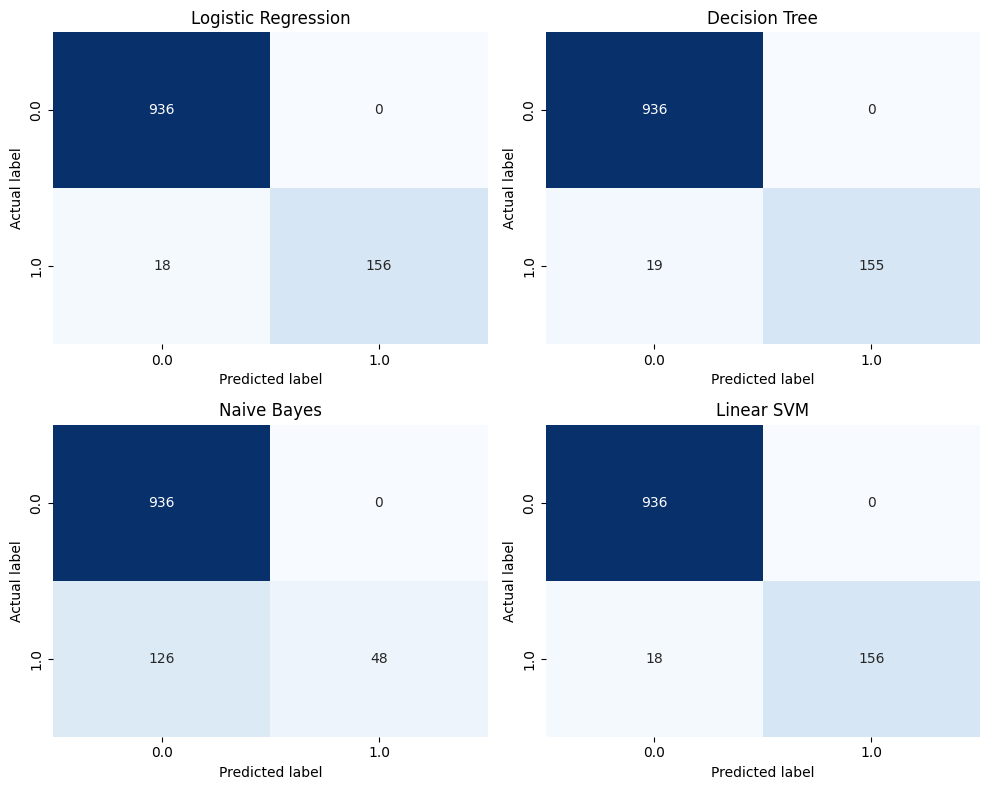

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for i, item in enumerate(model_predictions):
    name = item[0]
    predictions = item[1]

    confusion = predictions.groupBy("label", "prediction").count().toPandas()
    confusion = confusion.pivot(index="label", columns="prediction", values="count").fillna(0)
    confusion = confusion.reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0)

    ax = axes[i // 2, i % 2]
    sns.heatmap(confusion, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

## 12. Compare model performance

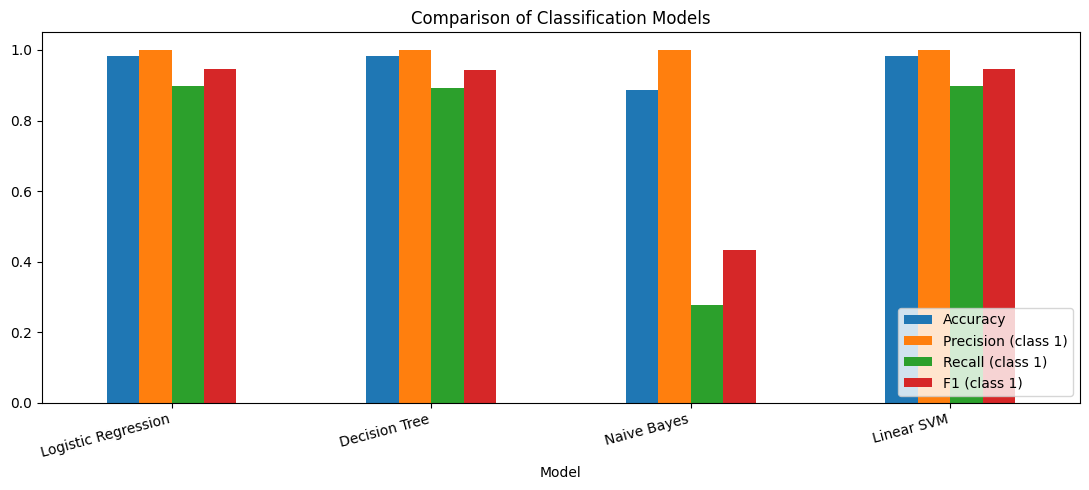

In [41]:
results.set_index("Model")[
    ["Accuracy", "Precision (class 1)", "Recall (class 1)", "F1 (class 1)"]
].plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))

plt.title("Comparison of Classification Models")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()